# Data Preprocessing

## Download & export data tables

### Download Microsoft OHLCV with `yfinance` library

In [1]:
import yfinance as yf

In [11]:
ticker = 'NVDA'
df_NVDA = yf.download(ticker)
df_NVDA

[*********************100%***********************]  1 of 1 completed


Price,Adj Close,Close,High,Low,Open,Volume
Ticker,NVDA,NVDA,NVDA,NVDA,NVDA,NVDA
Date,,,,,,
1999-01-22,0.037615,0.041016,0.048828,0.038802,0.043750,2714688000
1999-01-25,0.041556,0.045313,0.045833,0.041016,0.044271,510480000
1999-01-26,0.038331,0.041797,0.046745,0.041146,0.045833,343200000
1999-01-27,0.038212,0.041667,0.042969,0.039583,0.041927,244368000
1999-01-28,0.038092,0.041536,0.041927,0.041276,0.041667,227520000
...,...,...,...,...,...,...
2024-12-30,137.490005,137.490005,140.270004,134.020004,134.830002,167734700
2024-12-31,134.289993,134.289993,138.070007,133.830002,138.029999,155659200


### Download any ticker

**Search for the ticker code**

YFinance: https://finance.yahoo.com/

- [x] Microsoft: MSFT
- [ ] Bitcoin: ???

In [3]:
ticker = 'BTC-USD'
df_BTC = yf.download(ticker)
df_BTC

[*********************100%***********************]  1 of 1 completed


Price,Adj Close,Close,High,Low,Open,Volume
Ticker,BTC-USD,BTC-USD,BTC-USD,BTC-USD,BTC-USD,BTC-USD
Date,,,,,,
2014-09-17,457.334015,457.334015,468.174011,452.421997,465.864014,21056800
2014-09-18,424.440002,424.440002,456.859985,413.104004,456.859985,34483200
2014-09-19,394.795990,394.795990,427.834991,384.532013,424.102997,37919700
2014-09-20,408.903992,408.903992,423.295990,389.882996,394.673004,36863600
2014-09-21,398.821014,398.821014,412.425995,393.181000,408.084991,26580100
...,...,...,...,...,...,...
2025-01-02,96886.875000,96886.875000,97739.820312,94201.570312,94416.289062,46009564411
2025-01-03,98107.429688,98107.429688,98956.914062,96034.617188,96881.726562,35611391163


## Visualize the data with plotly

https://plotly.com/python/candlestick-charts/

In [4]:
import plotly as plt
import plotly.express as px
import plotly.graph_objects as go

In [12]:
# pyo.init_notebook_mode()
# pio.renderers.default = "notebook"
df = df_NVDA
df.columns = df.columns.droplevel(1)

fig = go.Figure(data=[go.Candlestick(x=df.index,
                open=df['Open'],
                high=df['High'],
                low=df['Low'],
                close=df['Close'])])

fig.show()

In [6]:
df = df_BTC
df.columns = df.columns.droplevel(1)

fig = go.Figure(data=[go.Candlestick(x=df.index,
                open=df['Open'],
                high=df['High'],
                low=df['Low'],
                close=df['Close'])])

fig.show()

## Export the data

### Microsoft data

#### Drop `Adj Close`

- To not confuse the `Close` and `Adj Close`

In [13]:
df_NVDA = df_NVDA.drop(columns='Adj Close')

#### To Excel

In [14]:
df_NVDA.to_excel('data/Nvidia_Stock_Price_Historical_Daily.xlsx')

#### To CSV

- Less size in memory

In [16]:
df_NVDA.to_csv('data/Nvidia_Stock_Price_Historical_Daily.csv')

### Bitcoin data altogether

#### Define ticker

In [17]:
ticker = 'BTC-USD'
ticker

'BTC-USD'

#### Download OLHVC

In [18]:
df_ticker = yf.download(ticker)
df_ticker

[*********************100%***********************]  1 of 1 completed


Price,Adj Close,Close,High,Low,Open,Volume
Ticker,BTC-USD,BTC-USD,BTC-USD,BTC-USD,BTC-USD,BTC-USD
Date,,,,,,
2014-09-17,457.334015,457.334015,468.174011,452.421997,465.864014,21056800
2014-09-18,424.440002,424.440002,456.859985,413.104004,456.859985,34483200
2014-09-19,394.795990,394.795990,427.834991,384.532013,424.102997,37919700
2014-09-20,408.903992,408.903992,423.295990,389.882996,394.673004,36863600
2014-09-21,398.821014,398.821014,412.425995,393.181000,408.084991,26580100
...,...,...,...,...,...,...
2025-01-02,96886.875000,96886.875000,97739.820312,94201.570312,94416.289062,46009564411
2025-01-03,98107.429688,98107.429688,98956.914062,96034.617188,96881.726562,35611391163


#### Create file path

In [79]:
file_path = f'data/{ticker}.xlsx'
file_path

'data/BTC-USD.xlsx'

#### Export to Excel

In [79]:
df_ticker.to_excel(file_path)

'data/BTC-USD.xlsx'

#### Export to CSV

In [79]:
df_ticker.to_excel(f'data/{ticker}.csv')

'data/BTC-USD.xlsx'

#### Snippet

In [20]:
ticker = 'BTC-USD'
df_ticker = yf.download(ticker)
df_ticker.to_excel(f'data/{ticker}.xlsx')
df_ticker.to_csv(f'data/{ticker}.csv')

[*********************100%***********************]  1 of 1 completed


## [ ] Data Preprocessing

In [ ]:
???

,Open,High,Low,Close,Volume,change_tomorrow,change_tomorrow_direction
Date,,,,,,,
2016-12-08,56.325228,56.582507,55.902560,56.058762,21220800,-1.549143,DOWN
2016-12-09,56.214968,56.959234,56.169027,56.940857,27349400,-0.321692,DOWN
...,...,...,...,...,...,...,...
2023-03-14,256.750000,261.070007,255.860001,260.790009,33620300,-1.751806,DOWN
2023-03-15,259.980011,266.480011,259.209991,265.440002,46028000,-3.895731,DOWN


### Load the data

In [22]:
import pandas as pd

df_nvidia = pd.read_excel(
    'data/Nvidia_Stock_Price_Historical_Daily.xlsx',
    parse_dates=['Date'], index_col=0
)

df_nvidia

,Close,High,Low,Open,Volume
Date,,,,,
1999-01-22,0.041016,0.048828,0.038802,0.043750,2714688000
1999-01-25,0.045313,0.045833,0.041016,0.044271,510480000
1999-01-26,0.041797,0.046745,0.041146,0.045833,343200000
1999-01-27,0.041667,0.042969,0.039583,0.041927,244368000
1999-01-28,0.041536,0.041927,0.041276,0.041667,227520000
...,...,...,...,...,...
2024-12-30,137.490005,140.270004,134.020004,134.830002,167734700
2024-12-31,134.289993,138.070007,133.830002,138.029999,155659200
2025-01-02,138.309998,138.880005,134.630005,136.000000,198247200


### Filter the data

![](src/Microsoft_x_LinkedIn.png)

In [26]:
df_nvidia_Mellanox = df_nvidia.loc['2019-03-11':,:].copy()

## Create new columns

### Tomorrow's percentage change

In [27]:
df_nvidia_Mellanox['change_tomorrow'] = df_nvidia_Mellanox.Close.pct_change(-1) * 100 * -1

In [28]:
df_nvidia_Mellanox

,Close,High,Low,Open,Volume,change_tomorrow
Date,,,,,,
2019-03-11,4.028500,4.051500,3.742250,3.789750,859728000,0.849129
2019-03-12,4.063000,4.109750,3.979750,4.056500,579576000,3.617594
2019-03-13,4.215500,4.245000,4.093250,4.100750,768900000,-1.848271
2019-03-14,4.139000,4.236750,4.131250,4.224750,519384000,2.502804
2019-03-15,4.245250,4.288250,4.179000,4.182500,661484000,-0.509029
...,...,...,...,...,...,...
2024-12-30,137.490005,140.270004,134.020004,134.830002,167734700,-2.382912
2024-12-31,134.289993,138.070007,133.830002,138.029999,155659200,2.906517
2025-01-02,138.309998,138.880005,134.630005,136.000000,198247200,4.263864


In [29]:
df_nvidia_Mellanox = df_nvidia_Mellanox.dropna().copy()

### Did the stock go up or down?

In [31]:
import numpy as np

In [32]:
df_nvidia_Mellanox['change_tomorrow_direction'] = np.where(df_nvidia_Mellanox.change_tomorrow > 0, 'UP', 'DOWN')

In [33]:
df_nvidia_Mellanox.change_tomorrow_direction.value_counts()

change_tomorrow_direction
UP      798
DOWN    668
Name: count, dtype: int64

<Axes: xlabel='Date'>

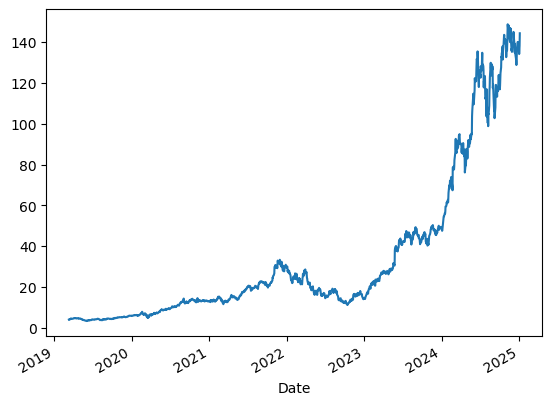

In [34]:
df_nvidia_Mellanox.Close.plot()

## Export preprocessed DataFrame into an Excel

In [35]:
df_nvidia_Mellanox.to_excel('data/Nvidia_Mellanox_Processed.xlsx')